In [1]:
from pathlib import Path
import re
import pandas as pd
 
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [2]:
RAW = Path("../datos")
archivos = sorted(RAW.rglob("*.csv"))
print([a.name for a in archivos])

['clickstream.csv', 'productos.csv', 'transacciones.csv', 'usuarios.csv']


In [3]:
raw = {a.stem: pd.read_csv(a, dtype=str, keep_default_na=True) for a in archivos}
for nombre, df in raw.items():
    print(f"\n=== {nombre} ===")
    display(df.head(5)) if "display" in globals() else print(df.head(5))


=== clickstream ===
  evento_id sesion_id usuario_id             timestamp tipo_evento       sku  termino_busqueda dispositivo                                         user_agent
0  E1005629   S201123        NaN   2025-03-22 00:56:38       vista  NX-11438               NaN       movil  Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...
1  E1004553   S200898        NaN  2026-05-09T16:19:23Z       vista  NX-11037               NaN  escritorio  Mozilla/5.0 (Linux; Android 14; SM-A546E) Appl...
2  E1023204   S204770    U100651  2025-10-08T06:37:26Z    busqueda       NaN  tarjeta de video       movil  Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...
3  E1014010   S202845        NaN  2025-02-25T16:03:32Z       vista  NX-10191               NaN       movil  Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...
4  E1006093   S201218    U100072   2025-04-12 12:34:30        clic  NX-10539               NaN  escritorio  Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...

=== productos ===
        sku 

In [4]:
def perfil_columnas(df):
    return pd.DataFrame({
        "nulos": df.isna().sum(),
        "%nulos": (df.isna().mean() * 100).round(1),
        "unicos": df.nunique(),
        "ejemplo": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

In [5]:
resumen = []
for nombre, df in raw.items():
    resumen.append({
        "archivo": nombre, "filas": len(df), "columnas": df.shape[1],
        "nulos_totales": int(df.isna().sum().sum()),
        "filas_duplicadas": int(df.duplicated().sum()),
    })
    print(f"\n--- {nombre} ---")
    print(perfil_columnas(df))
pd.DataFrame(resumen)


--- clickstream ---
                  nulos  %nulos  unicos                                            ejemplo
evento_id             0     0.0   29077                                           E1005629
sesion_id             0     0.0    6000                                            S201123
usuario_id        17653    60.2    2411                                            U100651
timestamp             0     0.0   29060                                2025-03-22 00:56:38
tipo_evento           0     0.0      14                                              vista
sku                6289    21.4    1439                                           NX-11438
termino_busqueda  23051    78.6      16                                   tarjeta de video
dispositivo           0     0.0       7                                              movil
user_agent            0     0.0      11  Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...

--- productos ---
              nulos  %nulos  unicos              e


--- transacciones ---
                 nulos  %nulos  unicos              ejemplo
pedido_id            0     0.0   17146              P503740
linea                0     0.0       4                    1
usuario_id          93     0.4    4224              U102528
sku                  0     0.0    1201             NX-10196
fecha                0     0.0   19165  2024-09-12 02:24:42
cantidad             0     0.0       9                    1
precio_unitario    440     2.0   17446                22335
descuento         8642    39.0    4884                    0
total                0     0.0   18753                22335
canal                0     0.0       7               tienda
estado               0     0.0       4               pagado

--- usuarios ---
                  nulos  %nulos  unicos      ejemplo
usuario_id            0     0.0    4000      U103808
fecha_registro        0     0.0    2833   2023-04-19
region                0     0.0      33     COQUIMBO
comuna              304    

,archivo,filas,columnas,nulos_totales,filas_duplicadas
0,clickstream,29340,9,46993,263
1,productos,1531,9,227,31
2,transacciones,22187,11,9175,186
3,usuarios,4026,8,1487,26


In [6]:
# %% [markdown]
# ## 2. Claves: unicidad y duplicados por clave
# Una clave candidata es una columna que empieza con "id" o termina en "_id".
 
# %%
def candidatas_clave(df):
    return [c for c in df.columns if re.search(r"(^id|_id$|^id_)", c.lower())]
 
for nombre, df in raw.items():
    for c in candidatas_clave(df):
        dup = df[c].dropna().duplicated().sum()
        print(f"{nombre}.{c}: {df[c].nunique()} únicos, "
              f"{dup} repetidos, {df[c].isna().sum()} nulos")

clickstream.evento_id: 29077 únicos, 263 repetidos, 0 nulos
clickstream.sesion_id: 6000 únicos, 23340 repetidos, 0 nulos
clickstream.usuario_id: 2411 únicos, 9276 repetidos, 17653 nulos
transacciones.pedido_id: 17146 únicos, 5041 repetidos, 0 nulos
transacciones.usuario_id: 4224 únicos, 17870 repetidos, 93 nulos
usuarios.usuario_id: 4000 únicos, 26 repetidos, 0 nulos


In [7]:
def variantes(df, max_unicos=60):
    for c in df.columns:
        s = df[c].dropna()
        if 1 < s.nunique() <= max_unicos:
            norm = s.str.strip().str.lower()
            if s.nunique() != norm.nunique():
                print(f"  {c}: {s.nunique()} crudos -> {norm.nunique()} normalizados")
                print("   ", sorted(s.unique())[:15])
 
for nombre, df in raw.items():
    print(f"\n--- {nombre} ---")
    variantes(df)


--- clickstream ---
  tipo_evento: 14 crudos -> 8 normalizados
    ['AGREGAR_CARRITO', 'BUSQUEDA', 'CLIC', 'Clic ', 'VISTA', 'Vista', 'add_to_cart', 'agregar_carrito', 'busqueda', 'clic', 'click', 'search', 'view', 'vista']
  dispositivo: 7 crudos -> 5 normalizados
    ['Escritorio', 'MOVIL', 'desktop', 'escritorio', 'mobile', 'movil', 'tablet']



--- productos ---
  categoria: 20 crudos -> 12 normalizados
    ['Almacenamiento', 'Audio', 'COMPONENTES', 'Cables', 'Cables y adaptadores', 'Componentes', 'Gaming', 'Monitores', 'NOTEBOOKS', 'Notebooks', 'Notebooks ', 'PERIFERICOS', 'Perifericos', 'Periféricos', 'Redes']
  activo: 7 crudos -> 6 normalizados
    ['0', '1', 'No', 'Si', 'TRUE', 'false', 'true']

--- transacciones ---
  canal: 7 crudos -> 4 normalizados
    ['App', 'TIENDA', 'WEB', 'app', 'movil', 'tienda', 'web']

--- usuarios ---
  region: 33 crudos -> 25 normalizados
    ['Antofagasta', 'Araucania', 'Araucanía', 'BIOBIO', 'Bio-Bio', 'Biobio', 'Biobío', 'Bío Bío', 'COQUIMBO', 'Coquimbo', 'Del Maule', 'LOS LAGOS', 'La Araucania', "Libertador B. O'Higgins", 'Los Lagos']


In [8]:
# %% [markdown]
# ## 4. Fechas y montos mal formados
# Intenta convertir y mira QUÉ falla (no solo cuántos).

# %%
def intentar_fecha(s):
    return pd.to_datetime(s, errors="coerce", dayfirst=True)

def intentar_monto(s):
    # Formato chileno: "$18.703" = 18703 (el punto es separador de MILES,
    # no decimal). Quita todo lo que no sea dígito o signo negativo.
    limpio = s.str.replace(r"[^\d\-]", "", regex=True)
    return pd.to_numeric(limpio, errors="coerce")

for nombre, df in raw.items():
    for c in df.columns:
        n = c.lower()
        if any(k in n for k in ("fecha", "date", "hora", "timestamp")):
            malas = df[c].notna() & intentar_fecha(df[c]).isna()
            print(f"{nombre}.{c} FECHA no parseable: {malas.sum()}  ej: {df.loc[malas, c].head(5).tolist()}")
        if any(k in n for k in ("monto", "amount", "valor", "precio", "total", "costo")):
            malas = df[c].notna() & intentar_monto(df[c]).isna()
            print(f"{nombre}.{c} MONTO no parseable: {malas.sum()}  ej: {df.loc[malas, c].head(5).tolist()}")


clickstream.timestamp FECHA no parseable: 13256  ej: ['2026-05-09T16:19:23Z', '2025-10-08T06:37:26Z', '2025-02-25T16:03:32Z', '2026-04-02 21:25:40-03:00', '27/02/2026 17:01']
productos.precio_lista MONTO no parseable: 0  ej: []
productos.costo MONTO no parseable: 0  ej: []
productos.fecha_alta FECHA no parseable: 1359  ej: ['2024-01-29', '2020-07-06', '2022-11-11', '15/09/2021', '2023-04-09']
transacciones.fecha FECHA no parseable: 16071  ej: ['2025-11-20 08:50:37', '2025-07-23 08:17:09', '2025-05-14 23:44:12', '2025-12-15 04:41:21', '11/10/2025 14:25']


transacciones.precio_unitario MONTO no parseable: 0  ej: []
transacciones.total MONTO no parseable: 0  ej: []
usuarios.fecha_registro FECHA no parseable: 1206  ej: ['10/01/2022', '23/01/2019', '17/05/2021', '01-09-2024', '26-12-2021']


C:\Users\Gabo\AppData\Local\Temp\ipykernel_17640\2473208835.py:7: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  return pd.to_datetime(s, errors="coerce", dayfirst=True)
C:\Users\Gabo\AppData\Local\Temp\ipykernel_17640\2473208835.py:7: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  return pd.to_datetime(s, errors="coerce", dayfirst=True)


In [9]:
# %% [markdown]
# ## 5. Numéricas: rangos, negativos y outliers
# En fraude, un outlier puede ser la señal. Marcar, no borrar a ciegas.
 
# %%
for nombre, df in raw.items():
    for c in df.columns:
        if any(k in c.lower() for k in ("monto", "amount", "valor", "edad", "age", "score", "cantidad")):
            v = intentar_monto(df[c].dropna())
            if v.notna().any():
                q1, q3 = v.quantile([.25, .75])
                iqr = q3 - q1
                fuera = ((v < q1 - 3 * iqr) | (v > q3 + 3 * iqr)).sum()
                print(f"{nombre}.{c}: min={v.min()}, mediana={v.median()}, max={v.max()}, "
                      f"negativos={(v < 0).sum()}, ceros={(v == 0).sum()}, extremos(3*IQR)={fuera}")

clickstream.user_agent: min=-2310.0, mediana=5.010064645373613e+22, max=5.010064641270201e+24, negativos=299, ceros=0, extremos(3*IQR)=5401
transacciones.cantidad: min=-3, mediana=1.0, max=5, negativos=234, ceros=305, extremos(3*IQR)=62
usuarios.edad: min=-38, mediana=45.0, max=999, negativos=26, ceros=84, extremos(3*IQR)=46


In [10]:
# %% [markdown]
# ## 6. Integridad referencial (huérfanos)
# Detecta columnas de clave compartidas entre tablas y cuenta registros sin pareja.
 
# %%
nombres = list(raw)
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        comunes = set(candidatas_clave(raw[a])) & set(candidatas_clave(raw[b]))
        for c in comunes:
            ka, kb = set(raw[a][c].dropna()), set(raw[b][c].dropna())
            print(f"{c}: {a} ({len(ka)}) vs {b} ({len(kb)}) | "
                  f"solo en {a}: {len(ka - kb)} | solo en {b}: {len(kb - ka)}")
 

usuario_id: clickstream (2411) vs transacciones (4224) | solo en clickstream: 48 | solo en transacciones: 1861
usuario_id: clickstream (2411) vs usuarios (4000) | solo en clickstream: 0 | solo en usuarios: 1589
usuario_id: transacciones (4224) vs usuarios (4000) | solo en transacciones: 297 | solo en usuarios: 73


In [11]:
# %% [markdown]
# ## 7. Variable objetivo y riesgo de fuga (leakage)
#
# **Descubrimiento**: NO existe una columna de fraude/etiqueta en ningún dataset.
# Se verificó: columnas de los 4 CSVs, README ("Caso 1" sin definir), historial
# git, y app/, tests/ y datos/preparar.py (todos vacíos).
#
# El dataset es sintético y tiene anomalías inyectadas (totales imposibles,
# compras anteriores al registro, usuario_id placeholder...).
# La propuesta de etiqueta DERIVADA y su evidencia están en la **sección 10**.

# %%
TARGET = None  # <- pendiente: confirmar con negocio la etiqueta real (ej. chargebacks)
for nombre, df in raw.items():
    for c in df.columns:
        if any(k in c.lower() for k in ("fraude", "fraud", "etiqueta", "label", "es_fraude")):
            print(f"Candidata a objetivo: {nombre}.{c}")
            print(df[c].value_counts(dropna=False))
print("Sin columna objetivo explícita. Ver propuesta de etiqueta derivada en la sección 10.")


Sin columna objetivo explícita. Ver propuesta de etiqueta derivada en la sección 10.


## 8. Visualizaciones exploratorias

Gráficos sobre los datos **crudos** para ver los problemas antes de limpiar:
composición de eventos, canales, montos, evolución temporal, regiones, edad y nulos.


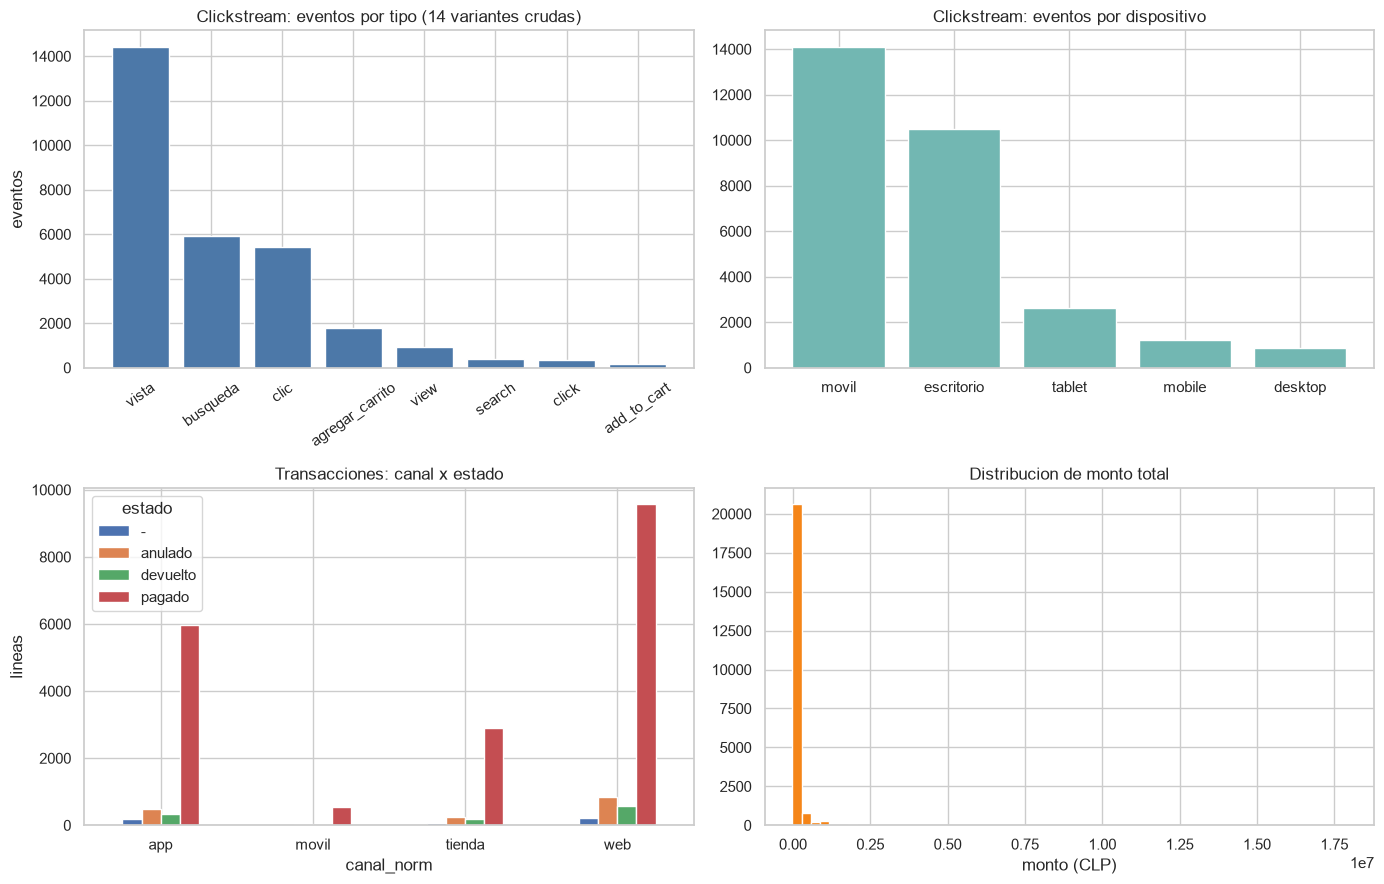

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Clickstream: eventos por tipo (variantes CRUDAS, 14 valores distintos)
ax = axes[0, 0]
tipos = raw["clickstream"]["tipo_evento"].str.strip().str.lower().value_counts()
ax.bar(tipos.index, tipos.values, color="#4C78A8")
ax.set_title("Clickstream: eventos por tipo (14 variantes crudas)")
ax.set_ylabel("eventos")
ax.tick_params(axis="x", rotation=35)

# 2) Clickstream: dispositivo (7 variantes crudas)
ax = axes[0, 1]
disp = raw["clickstream"]["dispositivo"].str.strip().str.lower().value_counts()
ax.bar(disp.index, disp.values, color="#72B7B2")
ax.set_title("Clickstream: eventos por dispositivo")
ax.tick_params(axis="x", rotation=0)

# 3) Transacciones: canal x estado
ax = axes[1, 0]
tx = raw["transacciones"].copy()
tx["canal_norm"] = tx["canal"].str.strip().str.lower()
pd.crosstab(tx["canal_norm"], tx["estado"]).plot(kind="bar", ax=ax)
ax.set_title("Transacciones: canal x estado")
ax.set_ylabel("lineas")
ax.tick_params(axis="x", rotation=0)

# 4) Distribucion de monto total
ax = axes[1, 1]
monto = intentar_monto(tx["total"]).dropna()
ax.hist(monto, bins=60, color="#F58518")
ax.set_title("Distribucion de monto total")
ax.set_xlabel("monto (CLP)")

plt.tight_layout()
plt.show()


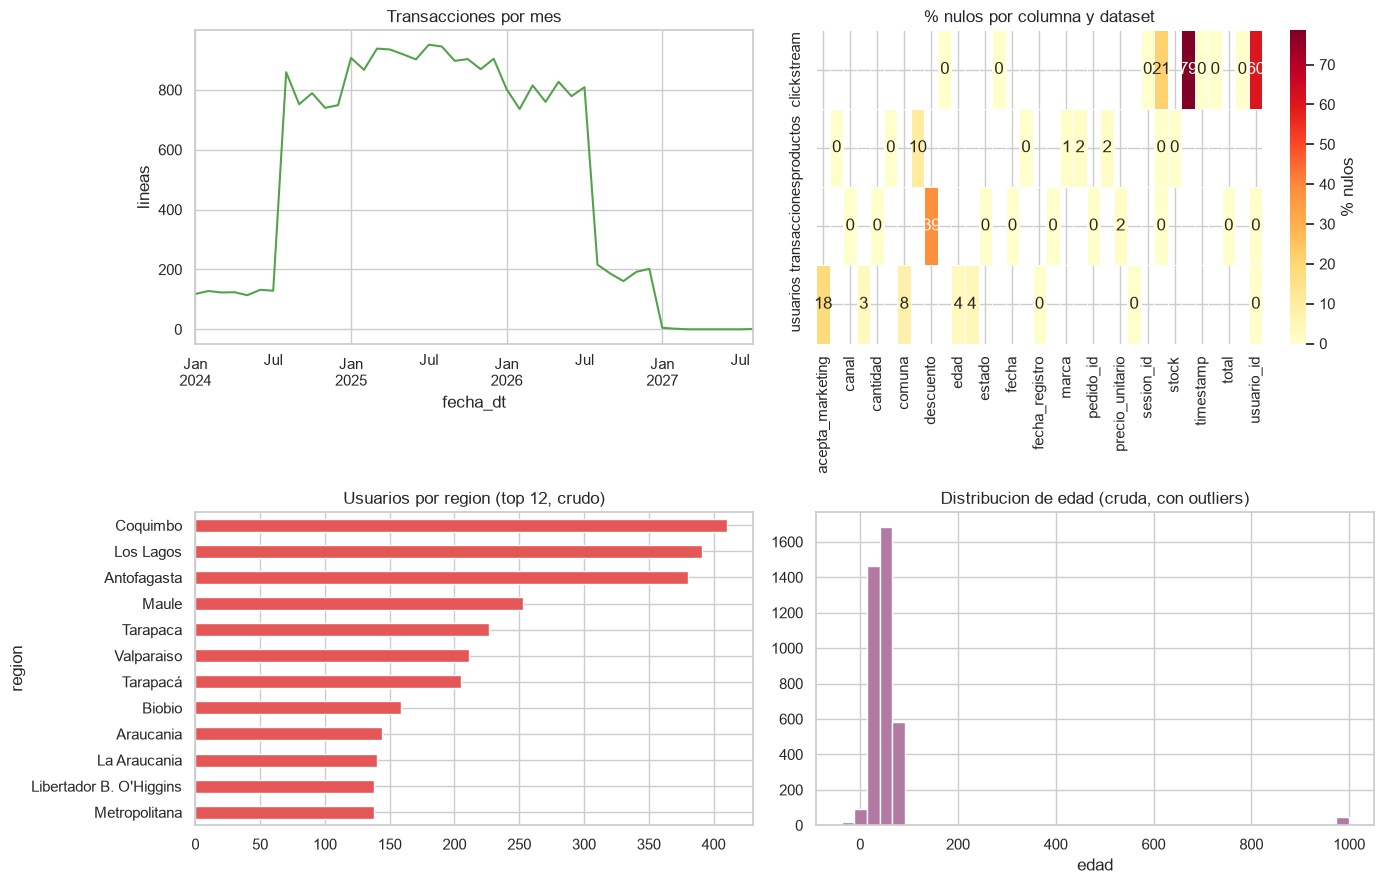

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Transacciones por mes (parser multi-formato: ver seccion 9)
ax = axes[0, 0]
tx_mes = tx.copy()
tx_mes["fecha_dt"] = pd.to_datetime(
    tx_mes["fecha"], errors="coerce", dayfirst=True, format="mixed", utc=True)
tx_mes.set_index("fecha_dt").resample("ME").size().plot(ax=ax, color="#54A24B")
ax.set_title("Transacciones por mes")
ax.set_ylabel("lineas")

# 2) Usuarios por region (nombres CRUDOS: notese la fragmentation)
ax = axes[1, 0]
regiones = raw["usuarios"]["region"].str.strip().str.title().value_counts().head(12)
regiones.sort_values().plot(kind="barh", ax=ax, color="#E45756")
ax.set_title("Usuarios por region (top 12, crudo)")

# 3) Edad: incluye valores invalidos (-38 a 999)
ax = axes[1, 1]
edad = pd.to_numeric(raw["usuarios"]["edad"], errors="coerce").dropna()
ax.hist(edad, bins=40, color="#B279A2")
ax.set_title("Distribucion de edad (cruda, con outliers)")
ax.set_xlabel("edad")

# 4) Mapa de calor de % nulos por columna y dataset
ax = axes[0, 1]
nulos = pd.DataFrame({n: df.isna().mean() * 100 for n, df in raw.items()}).T
sns.heatmap(nulos, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% nulos"}, linewidths=0.5)
ax.set_title("% nulos por columna y dataset")

plt.tight_layout()
plt.show()


## 9. Limpieza y normalización

A partir de los hallazgos de las secciones 3–6:

- **Texto**: `strip` + `lower` + sin tildes, luego mapeo a valores canónicos
- **Booleanos**: `true/1/Si/TRUE` → `True`; `false/0/No` → `False`
- **Fechas**: parser multi-formato (`format="mixed"`). El parser ingenuo de la sección 4
  fallaba en 13k–16k registros por los formatos mixtos; con este, **el 100% parsea**.
  ⚠️ Todo queda en UTC (los naive se interpretan como UTC). Si necesitas hora local
  de Chile: `.dt.tz_convert("America/Santiago")`.
- **Montos**: quita `$` y puntos de miles → numérico
- **Flags de calidad** (señales para revisar, **no** para borrar a ciegas):
  `total_difiere`, `es_devolucion`, `stock_negativo`, `edad_invalida`

Los datos originales quedan intactos en `raw`; la versión limpia queda en `clean`.


In [14]:
import unicodedata

# ---------- helpers ----------
def sin_tildes(x):
    if not isinstance(x, str):
        return x
    return "".join(c for c in unicodedata.normalize("NFKD", x) if not unicodedata.combining(c))

def normalizar_texto(s):
    """strip + lower + sin tildes: 'Biobío'/'BIOBIO'/'Bio-Bio' -> 'biobio'."""
    return s.str.strip().str.lower().map(sin_tildes)

def intentar_fecha_mixto(s):
    """Parser multi-formato: ISO, ISO con Z/offset y dd/mm/aaaa (con/sin hora). Todo a UTC."""
    return pd.to_datetime(s, errors="coerce", dayfirst=True, format="mixed", utc=True)

# ---------- diccionarios de mapeo ----------
MAP_BOOL = {"true": True, "1": True, "si": True,
            "false": False, "0": False, "no": False}

MAP_TIPO_EVENTO = {"vista": "vista", "view": "vista",
                   "clic": "clic", "click": "clic",
                   "busqueda": "busqueda", "search": "busqueda",
                   "agregar_carrito": "agregar_carrito", "add_to_cart": "agregar_carrito"}

MAP_DISPOSITIVO = {"escritorio": "escritorio", "desktop": "escritorio",
                   "movil": "movil", "mobile": "movil", "tablet": "tablet"}

MAP_CANAL = {"app": "app", "web": "web", "tienda": "tienda", "movil": "movil"}

MAP_CATEGORIA = {"notebooks": "notebooks", "monitores": "monitores", "redes": "redes",
                 "perifericos": "perifericos", "audio": "audio", "almacenamiento": "almacenamiento",
                 "gaming": "gaming", "componentes": "componentes", "cables": "cables",
                 "cables y adaptadores": "cables", "smartphones": "smartphones"}

MAP_REGION = {
    "antofagasta": "Antofagasta",
    "araucania": "Araucania", "la araucania": "Araucania",
    "biobio": "Biobio", "bio-bio": "Biobio", "bio bio": "Biobio",
    "coquimbo": "Coquimbo",
    "del maule": "Maule", "maule": "Maule",
    "los lagos": "Los Lagos",
    "libertador b. o'higgins": "O'Higgins", "o'higgins": "O'Higgins", "ohiggins": "O'Higgins",
    "metropolitana": "Metropolitana", "rm": "Metropolitana",
    "region metropolitana": "Metropolitana", "r. metropolitana": "Metropolitana",
    "tarapaca": "Tarapaca",
    "valparaiso": "Valparaiso", "v region": "Valparaiso",
}

clean = {}

# ---------- clickstream ----------
cs = raw["clickstream"].copy()
cs["tipo_evento"] = normalizar_texto(cs["tipo_evento"]).map(MAP_TIPO_EVENTO)
cs["dispositivo"] = normalizar_texto(cs["dispositivo"]).map(MAP_DISPOSITIVO)
cs["timestamp"] = intentar_fecha_mixto(cs["timestamp"])
clean["clickstream"] = cs

# ---------- productos ----------
pr = raw["productos"].copy()
pr["categoria"] = normalizar_texto(pr["categoria"]).map(MAP_CATEGORIA)
pr["marca"] = pr["marca"].str.strip().replace({"N/D": None})
pr["activo"] = normalizar_texto(pr["activo"]).map(MAP_BOOL)
pr["precio_lista"] = intentar_monto(pr["precio_lista"])
pr["costo"] = intentar_monto(pr["costo"])
pr["stock"] = pd.to_numeric(pr["stock"], errors="coerce")
pr["fecha_alta"] = intentar_fecha_mixto(pr["fecha_alta"])
pr["stock_negativo"] = pr["stock"] < 0
clean["productos"] = pr

# ---------- transacciones ----------
tx_c = raw["transacciones"].copy()
tx_c["canal"] = normalizar_texto(tx_c["canal"]).map(MAP_CANAL)
tx_c["estado"] = normalizar_texto(tx_c["estado"]).replace({"-": None})
tx_c["fecha"] = intentar_fecha_mixto(tx_c["fecha"])
tx_c["cantidad"] = pd.to_numeric(tx_c["cantidad"], errors="coerce")
tx_c["precio_unitario"] = intentar_monto(tx_c["precio_unitario"])
tx_c["descuento"] = intentar_monto(tx_c["descuento"]).fillna(0)
tx_c["total"] = intentar_monto(tx_c["total"])
tx_c["es_devolucion"] = tx_c["cantidad"] < 0
tx_c["total_esperado"] = tx_c["cantidad"] * tx_c["precio_unitario"] - tx_c["descuento"]
tx_c["total_difiere"] = (tx_c["total"] - tx_c["total_esperado"]).abs() > 1
clean["transacciones"] = tx_c

# ---------- usuarios ----------
us = raw["usuarios"].copy()
us["region"] = normalizar_texto(us["region"]).map(MAP_REGION)
us["comuna"] = us["comuna"].str.strip().str.title()
us["canal_captacion"] = normalizar_texto(us["canal_captacion"]).replace({"unknown": None})
us["email_valido"] = normalizar_texto(us["email_valido"]).map(MAP_BOOL)
us["acepta_marketing"] = normalizar_texto(us["acepta_marketing"]).map(MAP_BOOL)
us["edad"] = pd.to_numeric(us["edad"], errors="coerce")
us["edad_invalida"] = ~us["edad"].between(1, 100)
us["fecha_registro"] = intentar_fecha_mixto(us["fecha_registro"])
clean["usuarios"] = us

for nombre, df in clean.items():
    print(f"=== {nombre} ===")
    print(df.dtypes.to_string(), "\n")


=== clickstream ===
evento_id                           str
sesion_id                           str
usuario_id                          str
timestamp           datetime64[us, UTC]
tipo_evento                         str
sku                                 str
termino_busqueda                    str
dispositivo                         str
user_agent                          str 

=== productos ===
sku                               str
nombre                            str
categoria                         str
marca                          object
precio_lista                  float64
costo                         float64
stock                         float64
activo                           bool
fecha_alta        datetime64[us, UTC]
stock_negativo                   bool 

=== transacciones ===
pedido_id                          str
linea                              str
usuario_id                         str
sku                                str
fecha              datetime64[us, UTC]
c

In [15]:
# ---------- verificación post-limpieza ----------
print("Regiones:", sorted(clean["usuarios"]["region"].dropna().unique()))
print("Categorias:", sorted(clean["productos"]["categoria"].dropna().unique()))
print("Tipos de evento:", sorted(clean["clickstream"]["tipo_evento"].dropna().unique()))
print("Dispositivos:", sorted(clean["clickstream"]["dispositivo"].dropna().unique()))
print("Canales:", sorted(clean["transacciones"]["canal"].dropna().unique()))
print("Estados:", sorted(clean["transacciones"]["estado"].dropna().unique()))
print()
print("Rangos de fechas (UTC):")
for nombre, col in [("clickstream", "timestamp"), ("transacciones", "fecha"),
                    ("productos", "fecha_alta"), ("usuarios", "fecha_registro")]:
    s = clean[nombre][col]
    print(f"  {nombre}.{col}: {s.min()} -> {s.max()} | NaT: {int(s.isna().sum())}")
print()
print("Registros marcados (senales, no borrados):")
print(f"  transacciones con total != cant x precio - descuento: {int(clean['transacciones']['total_difiere'].sum())}")
print(f"  transacciones con cantidad negativa (devolucion): {int(clean['transacciones']['es_devolucion'].sum())}")
print(f"  productos con stock negativo: {int(clean['productos']['stock_negativo'].sum())}")
print(f"  usuarios con edad fuera de [1, 100]: {int(clean['usuarios']['edad_invalida'].sum())}")
print(f"  transacciones con estado '-' (desconocido): {int(clean['transacciones']['estado'].isna().sum())}")


Regiones: ['Antofagasta', 'Araucania', 'Biobio', 'Coquimbo', 'Los Lagos', 'Maule', 'Metropolitana', "O'Higgins", 'Tarapaca', 'Valparaiso']
Categorias: ['almacenamiento', 'audio', 'cables', 'componentes', 'gaming', 'monitores', 'notebooks', 'perifericos', 'redes', 'smartphones']
Tipos de evento: ['agregar_carrito', 'busqueda', 'clic', 'vista']
Dispositivos: ['escritorio', 'movil', 'tablet']
Canales: ['app', 'movil', 'tienda', 'web']
Estados: ['anulado', 'devuelto', 'pagado']

Rangos de fechas (UTC):
  clickstream.timestamp: 2024-01-08 08:13:22+00:00 -> 2026-12-08 01:55:59+00:00 | NaT: 0
  transacciones.fecha: 2024-01-08 01:28:52+00:00 -> 2027-08-02 00:00:00+00:00 | NaT: 0
  productos.fecha_alta: 2019-01-01 00:00:00+00:00 -> 2026-12-05 00:00:00+00:00 | NaT: 0
  usuarios.fecha_registro: 2019-01-01 00:00:00+00:00 -> 2027-10-02 00:00:00+00:00 | NaT: 0

Registros marcados (senales, no borrados):
  transacciones con total != cant x precio - descuento: 2244
  transacciones con cantidad negativ

## 10. Resumen de conclusiones

### Volumen
- **usuarios**: 4.026 registros · **transacciones**: 22.187 líneas (17.146 pedidos) · **productos**: 1.531 · **clickstream**: 29.340 eventos en 6.000 sesiones

### 🔎 Variable objetivo: NO existe (descubierta por análisis)
Ninguno de los 4 datasets tiene columna de fraude/etiqueta, y tampoco la definen el README, el historial git, ni `app/`, `tests/` o `datos/preparar.py` (vacíos). El "Caso 1" es un dataset **sintético con anomalías inyectadas**:

| Señal descubierta | Líneas/eventos | % |
|---|---|---|
| `total ≠ cantidad × precio − descuento` (aritmética imposible) | 2.244 | 10,1% |
| compra **anterior** al registro del usuario (865 usuarios, hasta 1.301 días antes) | 3.147 | 14,2% |
| `usuario_id` placeholder ("invitado" 94, "UNKNOWN" 93, vacío 93) | 280 | 1,3% |
| usuario huérfano (transacciona sin ficha en `usuarios.csv`) | 663 | 3,0% |
| total negativo / cantidad negativa | 130 / 234 | 0,6% / 1,1% |
| bots en clickstream (Scrapy, curl, Googlebot, SemrushBot, AhrefsBot) | 1.791 ev. | 6,1% |

**Propuesta de etiqueta derivada** (a nivel de línea de transacción):

```
sospechoso = total_difiere | total_negativo | cantidad_negativa
           | compra_antes_registro | usuario_huerfano
           | usuario_id en {"invitado", "UNKNOWN", vacío}
```

- ≥1 señal: 5.699 líneas (25,7%) → demasiado amplio
- **≥2 señales: 650 líneas (2,9%)** → tasa base realista para fraude
- **Alternativa**: si el objetivo de negocio es el resultado del pedido, `estado` es la etiqueta limpia (pagado 85,7% / anulado 7,3% / devuelto 5,0% / "-" 2,0%).

⚠️ Toda etiqueta derivada es un **proxy**: la etiqueta real de fraude (ej. chargebacks) solo la tiene el negocio. **Pendiente confirmación.**

### Calidad de datos (arreglar antes de modelar)
1. **Fechas con 4 formatos** (ISO, ISO con zona horaria, `dd/mm/aaaa`, `dd-mm-aaaa`): con `format="mixed"` el **100% parsea** (el parser ingenuo fallaba en 13k–16k). ⚠️ Todo queda en UTC.
2. **Montos en formato chileno** (`$18.703` = 18.703, punto de miles): 100% parseables si se interpreta bien. Un parser ingenuo los lee como decimales y **rompe la verificación de totales**.
3. **Valores fuera de rango**: edad de −38 a 999 (297, 7,4%), stock negativo (38, 2,5%).
4. **Categóricas fragmentadas** (normalizadas en `clean`): regiones 33→10, categorías 20→10, tipo_evento 14→4, canal 7→4, booleanos 7→2.
5. **Estado desconocido `-`**: 453 líneas (2,0%).
6. **Duplicados**: 263 eventos, 186 líneas, 31 productos y 26 `usuario_id` repetidos en `usuarios.csv`.
7. **Integridad referencial**: 297 usuarios con transacciones sin ficha; 60,2% de eventos clickstream sin `usuario_id` (tráfico anónimo).
8. **Nulos relevantes**: `descuento` 39% (tratado como 0 en `clean`), `usuario_id` clickstream 60%, `termino_busqueda` 79% (esperable: solo aplica a búsquedas), `edad` 3,5%.

### Riesgo de fuga (leakage)
- Sin etiqueta confirmada no se puede evaluar a fondo. Al definirla, ojo con columnas que solo existirían *después* del fraude (ej. `estado`, `descuento`) y con derivar la etiqueta de los mismos datos usados como features.

### Recomendaciones
- **No borrar** outliers, negativos ni duplicados a ciegas: en detección de fraude son señal. Marcar y revisar.
- Validaciones en ingest: formato único de fecha, montos numéricos (formato CLP), rango de edad, regla de cálculo de `total`.
- Resolver `usuario_id` anónimo/placeholder o aceptar cobertura parcial por usuario.
- Persistir `clean/` como capa intermedia antes del feature engineering.
